# 01b. EDA and preprocessing summary (report 2.1 EDA / 2.2 preprocessing)
- 입력: 01번에서 만든 `데이터_csv/영통구_행정동별_월별_학습데이터셋.csv` 와 원본 실거래가·인구현황
- 분석 대상: 모델에 쓰는 행 (기본 변수 결측이 없는 2024.03~2026.09, 372행)
- 목표 변수 분포 → 목표와 수치형 변수의 상관 → 변수 간 상관 히트맵 → 기초통계·이상치 후보 → 전처리 단계별 건수
- 그래프는 화면에 띄우고(plt.show) 보고서용으로 `figures/` 에도 저장
사전설치 : pip install pandas matplotlib seaborn

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 노트북에는 __file__이 없으므로 실행 위치(code 폴더 또는 ML 폴더)로 기준 폴더를 정함
BASE_DIR = (Path.cwd().parent if Path.cwd().name == "code" else Path.cwd())
DATA_DIR = BASE_DIR / "데이터_csv"
FIG_DIR = BASE_DIR / "figures"
FIG_DIR.mkdir(exist_ok=True)
DESCRIBE_PATH = DATA_DIR / "results_eda_describe.csv"

# 폰트지정 (행정동 한글 이름이 들어가므로 필요)
plt.rcParams["font.family"] = "Malgun Gothic"
# 마이너스 부호 깨짐 지정
plt.rcParams["axes.unicode_minus"] = False

In [2]:
# [CONFIG]
TARGET = "outflow"
CAT_FEATURES = ["dong", "month"]
NUM_FEATURES = [
    "price_m2",
    "price_chg_1m", "price_chg_3m",
    "price_chg_1m_lag2", "price_chg_1m_lag3",
    "trade_cnt", "trade_cnt_3m",
    "new_ratio", "build_year_avg",
    "pop_chg_rate_lag1", "population_lag1", "hh_size_lag1",
]
EXTRA_FEATURES = ["price_chg_12m"]     # 기본 모델에서는 제외, 상관 확인에만 포함
IQR_K = 1.5                            # 이상치 후보: Q1 - 1.5×IQR 미만 또는 Q3 + 1.5×IQR 초과

In [3]:
# Load data
raw = pd.read_csv(DATA_DIR / "영통구_행정동별_월별_학습데이터셋.csv")
df = raw.dropna(subset=CAT_FEATURES + NUM_FEATURES).reset_index(drop=True)
print(f"Dataset : {raw.shape} ({raw['ym'].min()} ~ {raw['ym'].max()})")
print(f"Model rows (no missing in base features): {df.shape} ({df['ym'].min()} ~ {df['ym'].max()})")

Dataset : (408, 18) (2023-12 ~ 2026-09)
Model rows (no missing in base features): (372, 18) (2024-03 ~ 2026-09)



Target counts: {0: 156, 1: 216} / outflow ratio 0.581
Outflow ratio by dong:
 dong
망포2동    0.129
망포1동    0.290
광교2동    0.516
영통3동    0.516
영통1동    0.581
영통2동    0.613
광교1동    0.613
원천동     0.645
매탄2동    0.710
매탄3동    0.742
매탄1동    0.774
매탄4동    0.839


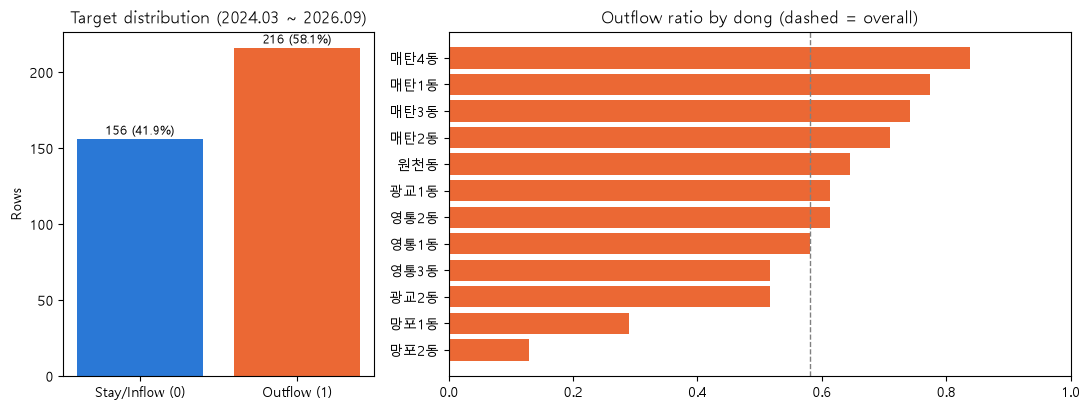

In [4]:
# Result 1: target distribution (report 2.1.1)
counts = df[TARGET].value_counts().sort_index()
print("\nTarget counts:", counts.to_dict(), f"/ outflow ratio {df[TARGET].mean():.3f}")
by_dong = df.groupby("dong")[TARGET].mean().sort_values()
print("Outflow ratio by dong:\n", by_dong.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1, 2]})
axes[0].bar(["Stay/Inflow (0)", "Outflow (1)"], counts.values, color=["#2a78d6", "#eb6834"])
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 3, f"{v} ({v / counts.sum():.1%})", ha="center", fontsize=9)
axes[0].set_title("Target distribution (2024.03 ~ 2026.09)")
axes[0].set_ylabel("Rows")
axes[1].barh(by_dong.index, by_dong.values, color="#eb6834")
axes[1].axvline(df[TARGET].mean(), color="gray", linestyle="--", linewidth=1)
axes[1].set_xlim(0, 1)
axes[1].set_title("Outflow ratio by dong (dashed = overall)")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_2_1_1_target.png", dpi=200)
plt.show()


Correlation with outflow:
 hh_size_lag1        -0.290
pop_chg_rate_lag1   -0.252
build_year_avg      -0.217
new_ratio           -0.199
trade_cnt_3m        -0.154
trade_cnt           -0.143
population_lag1     -0.128
price_m2            -0.081
price_chg_1m_lag2   -0.069
price_chg_12m       -0.012
price_chg_1m        -0.007
price_chg_1m_lag3    0.006
price_chg_3m         0.051


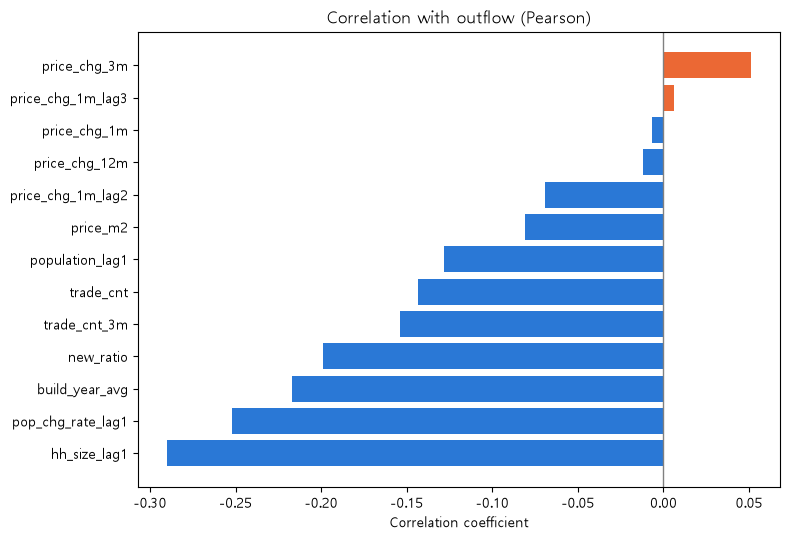

In [5]:
# Result 2: correlation between target and numeric features (report 2.1.3)
# 목표(0/1)와 각 수치형 변수의 피어슨 상관계수 (price_chg_12m은 결측이 아닌 행만으로 계산)
eda = raw.dropna(subset=CAT_FEATURES + NUM_FEATURES)
target_corr = eda[NUM_FEATURES + EXTRA_FEATURES].corrwith(eda[TARGET]).sort_values()
print("\nCorrelation with outflow:\n", target_corr.round(3).to_string())

plt.figure(figsize=(8, 5.5))
plt.barh(target_corr.index, target_corr.values,
         color=["#eb6834" if v > 0 else "#2a78d6" for v in target_corr.values])
plt.axvline(0, color="gray", linewidth=1)
plt.title("Correlation with outflow (Pearson)")
plt.xlabel("Correlation coefficient")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_2_1_3_target_corr.png", dpi=200)
plt.show()

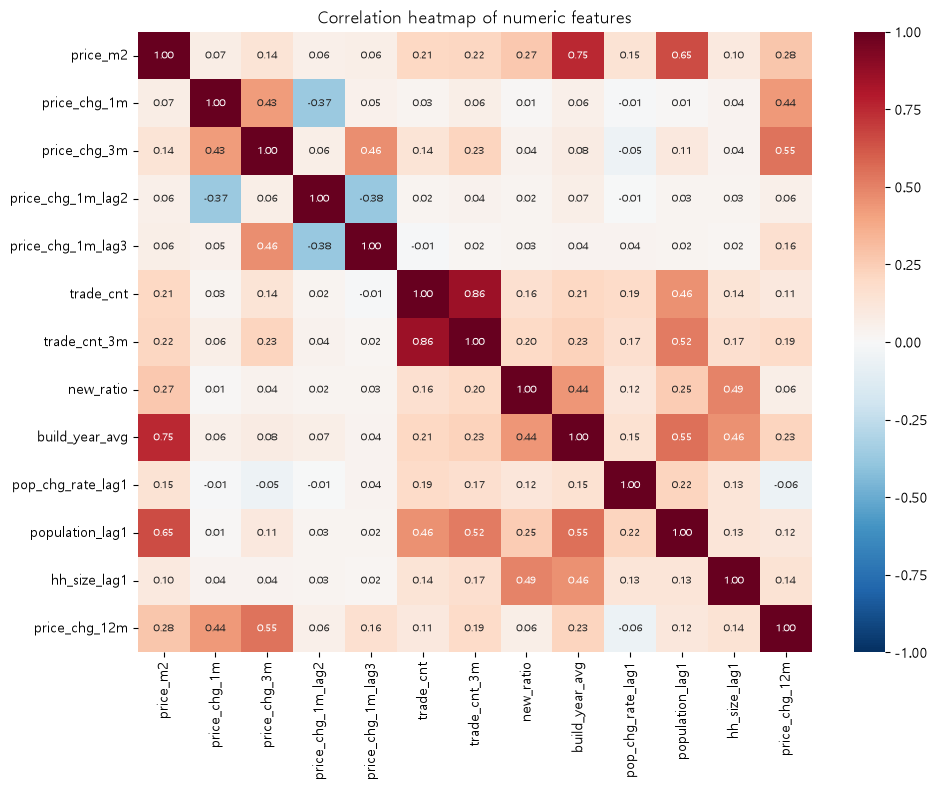


Highly correlated pairs (|r| >= 0.7):
           var1         var2     r
     trade_cnt trade_cnt_3m 0.858
build_year_avg     price_m2 0.753


In [6]:
# Result 3: correlation heatmap between features (report 2.1.4)
corr = eda[NUM_FEATURES + EXTRA_FEATURES].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, annot_kws={"size": 7})
plt.title("Correlation heatmap of numeric features")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_2_1_4_heatmap.png", dpi=200)
plt.show()

# 상관이 높은 변수 쌍 (|r| >= 0.7) → 다중공선성 확인
pairs = (corr.where(lambda c: ~c.isna()).stack().reset_index()
         .rename(columns={"level_0": "var1", "level_1": "var2", 0: "r"}))
pairs = pairs[(pairs["var1"] < pairs["var2"]) & (pairs["r"].abs() >= 0.7)].sort_values("r", key=abs, ascending=False)
print("\nHighly correlated pairs (|r| >= 0.7):\n", pairs.round(3).to_string(index=False))


Descriptive statistics:
                    count       mean        std        min        25%        50%        75%        max  outlier_cnt
price_m2           372.0    882.920    282.156    506.600    674.275    782.775   1067.700   1703.150            2
price_chg_1m       372.0      0.010      0.043     -0.198     -0.010      0.007      0.027      0.308           24
price_chg_3m       372.0      0.019      0.051     -0.289     -0.004      0.017      0.039      0.332           30
price_chg_1m_lag2  372.0      0.009      0.043     -0.198     -0.010      0.007      0.026      0.308           23
price_chg_1m_lag3  372.0      0.008      0.043     -0.198     -0.011      0.006      0.024      0.308           24
trade_cnt          372.0     39.460     24.959      2.000     20.000     36.000     53.250    134.000            5
trade_cnt_3m       372.0     38.927     21.821      3.667     22.000     37.667     53.417    117.667            5
new_ratio          372.0      0.039      0.095      0.

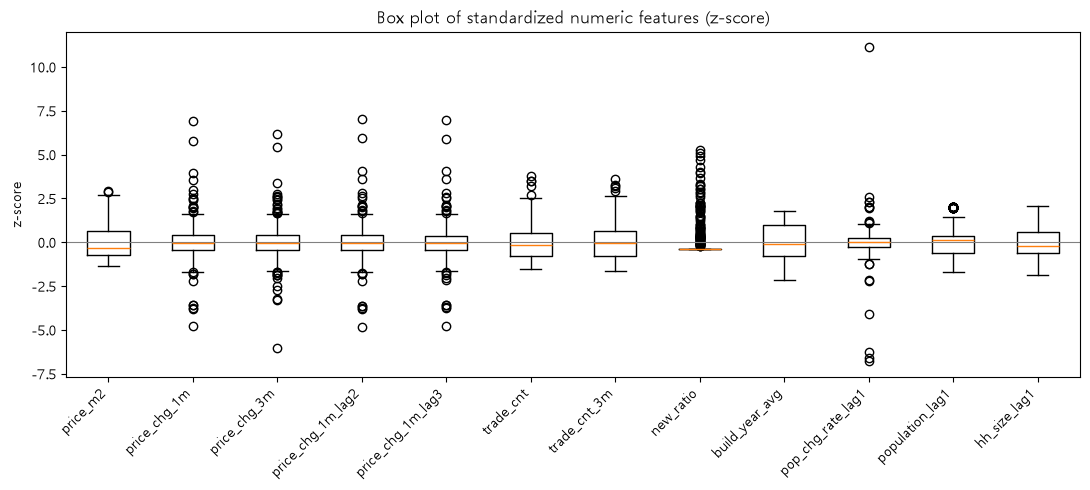


Largest population changes:
      ym dong  pop_chg
2025-04 망포2동     1600
2026-09 영통2동     -562
2026-09  원천동      517
2025-09  원천동      480
2024-09  원천동      426
2024-10  원천동      426
2025-03  원천동      352
2025-11 매탄1동     -328


In [7]:
# Result 4: descriptive statistics and outlier candidates (report 2.1.5)
desc = df[NUM_FEATURES + ["pop_chg"]].describe().T
q1, q3 = desc["25%"], desc["75%"]
iqr = q3 - q1
desc["outlier_cnt"] = [((df[c] < q1[c] - IQR_K * iqr[c]) | (df[c] > q3[c] + IQR_K * iqr[c])).sum()
                       for c in desc.index]
print("\nDescriptive statistics:\n", desc.round(3).to_string())
desc.round(4).to_csv(DESCRIBE_PATH, encoding="utf-8-sig")
print("Saved:", DESCRIBE_PATH)

# 단위가 달라서 표준화(z-score)한 뒤 상자그림으로 비교
z = (df[NUM_FEATURES] - df[NUM_FEATURES].mean()) / df[NUM_FEATURES].std()
plt.figure(figsize=(11, 5))
plt.boxplot(z.values, tick_labels=NUM_FEATURES)
plt.xticks(rotation=45, ha="right")
plt.axhline(0, color="gray", linewidth=0.8)
plt.title("Box plot of standardized numeric features (z-score)")
plt.ylabel("z-score")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_2_1_5_boxplot.png", dpi=200)
plt.show()

# 인구 증감이 큰 달 (신규 입주 등 일회성 변화 후보)
print("\nLargest population changes:\n",
      df.loc[df["pop_chg"].abs().sort_values(ascending=False).index[:8], ["ym", "dong", "pop_chg"]].to_string(index=False))

In [8]:
# Result 5: preprocessing step counts (report 2.2)
trades = pd.read_csv(DATA_DIR / "영통구_아파트_실거래가_2023.10-2026.10.csv", dtype={"번지": str})
pop = pd.read_csv(DATA_DIR / "영통구_행정동별_월별_인구현황.csv")
cancelled = (trades["해제여부"] != "N").sum()
partial = ((trades["해제여부"] == "N") & (trades["계약년월"].astype(str) == "202310")).sum()
print("\nPreprocessing steps:")
print(f"  Trades raw                 : {len(trades)} rows, {trades.shape[1]} columns")
print(f"  - cancelled trades removed : {cancelled}")
print(f"  - partial month 2023.10    : {partial}")
print(f"  Trades used                : {len(trades) - cancelled - partial}")
print(f"  Population raw             : {len(pop)} rows ({(pop['구분'] == '행정동').sum()} dong rows), {pop.shape[1]} columns")
print(f"  Dataset (dong × month)     : {raw.shape}")
print("  Missing count by column:\n", raw.isna().sum()[lambda s: s > 0].to_string())
print("  First month without missing (base features):", df["ym"].min(), f"→ {len(df)} rows")


Preprocessing steps:
  Trades raw                 : 17013 rows, 21 columns
  - cancelled trades removed : 800
  - partial month 2023.10    : 12
  Trades used                : 16201
  Population raw             : 468 rows (432 dong rows), 15 columns
  Dataset (dong × month)     : (408, 18)
  Missing count by column:
 price_chg_1m          12
price_chg_3m          36
price_chg_12m        144
price_chg_1m_lag2     24
price_chg_1m_lag3     36
trade_cnt_3m          24
  First month without missing (base features): 2024-03 → 372 rows
